## **Deep Learning Lab Assignment 3**

### **Multilayer Feedforward Neural Network (36-D features, 5 classes)**

**Project contributors - Team 17**:

- Mirthula M     (26120121)  
- Karthikeyan M  (26120004)

**Workflow of the project**

- No. of Input features : 36 
- No. of output classes : 5
- No. of hidden layers : 2  (30 nodes → 15 nodes)

we train this under every combination of:

- **Activation**: Tanh (β = 1.0) vs ReLU
- **Learning mode**: Pattern mode (SGD, batch size = 1) vs Mini-batch mode (5 subsets/epoch)
- **Update rule**: Delta rule (η = 0.8), Generalized delta rule (η = 0.8, α = 0.9 momentum), Adam

Hence a  2 × 2 × 3 = **12 combinations**. For each one we plot the training/validation error curves and report accuracy + confusion matrices on train/val/test data.

The model that uses Tanh as activation rule is Config1 and the one that use ReLU is defined as config2. 

At the end, for Config2 = ReLU, Mini-batch, Adam we repeat it with **mean-variance normalization** and **layer normalization** to see how much normalization actually helps.

### **1. Imports and Setup**

Importing essential libraries and using random seed for reproducibility 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import accuracy_score, confusion_matrix

# Fix seeds so results are reproducible across runs
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use GPU if available, else CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

Using device: cpu


### **2. Load Datasets**

The dataset is split into train / validation / test CSVs with no header row included.

In [2]:
DATA_DIR = "data"   # folder containing train_data.csv, train_label.csv, val_data.csv, val_label.csv, test_data.csv, test_label.csv

def load_split(split_name):
    '''Load one split (train/val/test) as float32 feature tensor + int64 label tensor.'''
    X = pd.read_csv(f"{DATA_DIR}/{split_name}_data.csv", header=None).values.astype(np.float32)
    y = pd.read_csv(f"{DATA_DIR}/{split_name}_label.csv", header=None).values.astype(np.int64).ravel()
    return torch.tensor(X), torch.tensor(y)

X_train, y_train = load_split("train")
X_val,   y_val   = load_split("val")
X_test,  y_test  = load_split("test")

print("Train :", X_train.shape, y_train.shape)
print("Val   :", X_val.shape,   y_val.shape)
print("Test  :", X_test.shape,  y_test.shape)

NUM_FEATURES = X_train.shape[1]
NUM_CLASSES  = int(y_train.max().item()) + 1
print(f"\nFeatures = {NUM_FEATURES}, Classes = {NUM_CLASSES}")

Train : torch.Size([2000, 36]) torch.Size([2000])
Val   : torch.Size([500, 36]) torch.Size([500])
Test  : torch.Size([500, 36]) torch.Size([500])

Features = 36, Classes = 5


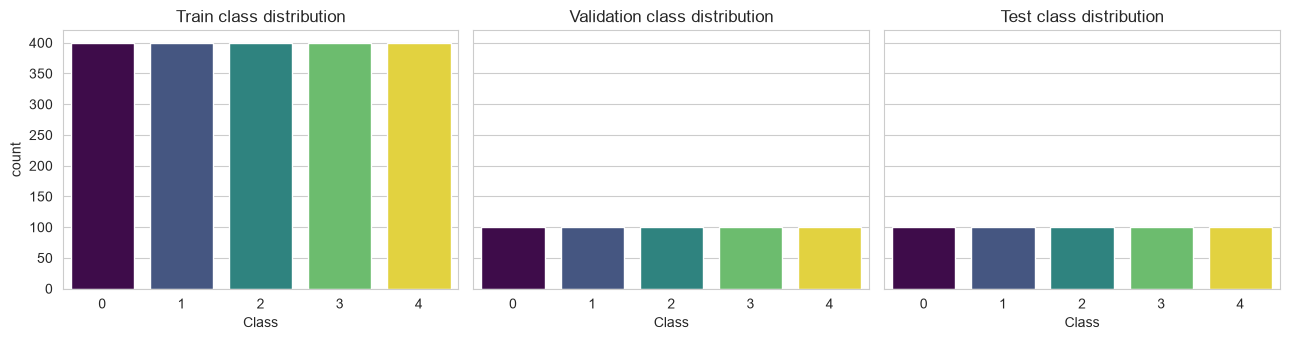

In [3]:
# check how balanced are the classes across the three splits
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, y) in zip(axes, [("Train", y_train), ("Validation", y_val), ("Test", y_test)]):
    sns.countplot(x=y.numpy(), ax=ax, hue=y.numpy(), palette="viridis", legend=False)
    ax.set_title(f"{name} class distribution")
    ax.set_xlabel("Class")
plt.tight_layout()
plt.show()

**Conclusion**

The class distribution is balanced across the training, validation, and test datasets. Each class has approximately the same number of samples within each split. This indicates that there is no significant class imbalance, so the model's accuracy should not be strongly biased toward any particular class.

### **3. Model Architecture**

In [4]:
class TanhBeta(nn.Module):
    '''Hyperbolic tangent activation with an explicit slope parameter beta: phi(v) = tanh(beta * v).'''
    def __init__(self, beta: float = 1.0):
        super().__init__()
        self.beta = beta

    def forward(self, x):
        return torch.tanh(self.beta * x)


class MLP(nn.Module):
    '''
    Feedforward network with two hidden layers (30 then 15 nodes).
    - activation: "tanh" or "relu", used in both hidden layers
    - use_layernorm: if True, applies LayerNorm right after each hidden linear layer
                      (before the activation) -- used only in the normalization experiment
    - output layer returns raw logits; softmax is applied implicitly by nn.CrossEntropyLoss
    '''
    def __init__(self, in_dim=36, h1=30, h2=15, out_dim=5,
                 activation="tanh", beta=1.0, use_layernorm=False):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.fc3 = nn.Linear(h2, out_dim)

        self.use_layernorm = use_layernorm
        if use_layernorm:
            self.ln1 = nn.LayerNorm(h1)
            self.ln2 = nn.LayerNorm(h2)

        self.activation = TanhBeta(beta) if activation == "tanh" else nn.ReLU()

    def forward(self, x):
        x = self.fc1(x)
        if self.use_layernorm:
            x = self.ln1(x)
        x = self.activation(x)

        x = self.fc2(x)
        if self.use_layernorm:
            x = self.ln2(x)
        x = self.activation(x)

        return self.fc3(x)   # logits (softmax handled by the loss function)

### **4. Training Configuration Helpers**

We have created two training helpers that can help us complete the training of 12 configuration variations

- `make_optimizer` maps the three "update rules" from the assignment onto PyTorch optimizers:
  - **Delta rule** → plain SGD (η = 0.8, no momentum)
  - **Generalized delta rule** → SGD with momentum (η = 0.8, α = 0.9)
  - **AdaM rule** → `torch.optim.Adam` (default learning rate)

- `make_dataloader` maps the two "learning modes" onto batch sizes:
  - **Pattern mode** → one sample at a time
  - **Mini-batch mode** → the training set is split into 5 subsets per epoch

In [5]:
def make_optimizer(model, rule):
    if rule == "delta":          # plain delta rule, no momentum
        return torch.optim.SGD(model.parameters(), lr=0.8, momentum=0.0)
    elif rule == "gdelta":       # generalized delta rule = delta rule + momentum term
        return torch.optim.SGD(model.parameters(), lr=0.8, momentum=0.9)
    elif rule == "adam":
        return torch.optim.Adam(model.parameters(), lr=0.001)
    else:
        raise ValueError(f"Unknown update rule: {rule}")


def make_dataloader(X, y, mode, num_subsets=5):
    if mode == "pattern":
        batch_size = 1
    elif mode == "minibatch":
        batch_size = int(np.ceil(len(X) / num_subsets))   # splits training data into `num_subsets` batches/epoch
    else:
        raise ValueError(f"Unknown learning mode: {mode}")
    dataset = TensorDataset(X, y)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)

### **5. Training Loop with the Stopping Criterion**

Training stops when the change in average training error becomes smaller than `tol = 0.001` for 5 consecutive epochs. A minimum of 20 epochs is used to avoid stopping too early.

- **Gradient clipping:** Since η = 0.8 is large for the delta rules, gradient clipping is used to make training more stable. 
Adam is left unclipped because it already adapts the updates.
- **Best validation model:** We save the model with the highest validation accuracy instead of always using the final epoch.
- **Epoch limits:** Pattern mode uses 60 epochs, while mini-batch mode uses 300 epochs because their training behaviour is different.

In [6]:
def train_model(activation, mode, rule, use_layernorm=False,
                 X_tr=None, y_tr=None, X_v=None, y_v=None,
                 tol=1e-3, patience=5, min_epochs=20, verbose=True):
    '''
    Trains one MLP under a given (activation, learning-mode, update-rule) combination.
    Returns the model with the best validation-accuracy weights found during training,
    plus the per-epoch train/val loss history.
    '''
    torch.manual_seed(SEED)   # reset the seed so every combination starts from the same init

    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_v  = X_val   if X_v  is None else X_v
    y_v  = y_val   if y_v  is None else y_v

    model = MLP(in_dim=NUM_FEATURES, out_dim=NUM_CLASSES,
                activation=activation, beta=1.0, use_layernorm=use_layernorm).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = make_optimizer(model, rule)
    loader = make_dataloader(X_tr, y_tr, mode)

    # rule-aware gradient clipping 
    if rule == "adam":
        clip_value = None                                  
    elif mode == "pattern" and rule == "gdelta":
        clip_value = 0.01                                 
    else:
        clip_value = 0.1

    max_epochs = 60 if mode == "pattern" else 300           

    X_v_dev, y_v_dev = X_v.to(device), y_v.to(device)

    train_losses, val_losses = [], []
    prev_train_loss, stall_count = None, 0
    best_val_acc, best_state = -1.0, None

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            if clip_value is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_value)
            optimizer.step()
            running_loss += loss.item() * len(xb)
        train_loss = running_loss / len(X_tr)
        train_losses.append(train_loss)

        # validation error/accuracy for this epoch (no gradient updates)
        model.eval()
        with torch.no_grad():
            val_logits = model(X_v_dev)
            val_loss = criterion(val_logits, y_v_dev).item()
            val_acc = (val_logits.argmax(dim=1) == y_v_dev).float().mean().item()
        val_losses.append(val_loss)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        # stopping criterion: change in average training error below threshold
        if prev_train_loss is not None and abs(prev_train_loss - train_loss) < tol:
            stall_count += 1
        else:
            stall_count = 0
        prev_train_loss = train_loss

        if verbose and (epoch % 20 == 0 or epoch == 1):
            print(f"  epoch {epoch:3d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")

        if epoch >= min_epochs and stall_count >= patience:
            if verbose:
                print(f"  stopping criterion met at epoch {epoch} (train error plateaued)")
            break
        if epoch == max_epochs and verbose:
            print(f"  reached max_epochs ({max_epochs}) without the stopping criterion firing "
                  f"-- this combination likely hasn't settled into a stable minimum")

    model.load_state_dict(best_state)   # keep the best-validation-accuracy weights

    history = {"train_loss": train_losses, "val_loss": val_losses, "epochs_run": epoch}
    return model, history

### **6. Evaluation Utilities**

Given a trained model and a data split, compute the predicted classes, accuracy, and confusion matrix. 

In [7]:
def evaluate_model(model, X, y):
    '''Returns (accuracy, confusion_matrix, predictions) for a trained model on data (X, y).'''
    model.eval()
    with torch.no_grad():
        logits = model(X.to(device))
        preds = logits.argmax(dim=1).cpu().numpy()
    y_np = y.numpy()
    acc = accuracy_score(y_np, preds)
    cm = confusion_matrix(y_np, preds, labels=list(range(NUM_CLASSES)))
    return acc, cm, preds

### **7. Plotting Utilities**

Two helper functions used for every combination:
- `plot_error_curves` — training vs validation error against epoch
- `plot_confusion_matrices` — side-by-side heatmaps for train/val/test

In [8]:
def plot_error_curves(history, title):
    plt.figure(figsize=(6, 4))
    plt.plot(history["train_loss"], label="Training error")
    plt.plot(history["val_loss"], label="Validation error")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy error")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_confusion_matrices(cm_train, cm_val, cm_test, title):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, cm, name in zip(axes, [cm_train, cm_val, cm_test], ["Train", "Validation", "Test"]):
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES))
        ax.set_title(f"{name} confusion matrix")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### **8. Experiment 1 — All 12 Baseline Combinations**

We train all 12 combinations of activation function, learning mode, and update rule. For each combination, we record the training results, confusion matrices, and accuracy. Here Pattern mode uses 60 epochs, while mini-batch uses 300 epochs.


Training: Tanh (beta=1.0) | Pattern mode | Delta rule
  epoch   1 | train loss 1.6200 | val loss 1.5071 | val acc 0.366
  epoch  20 | train loss 1.6071 | val loss 1.9136 | val acc 0.466
  epoch  40 | train loss 1.6146 | val loss 1.7940 | val acc 0.508
  epoch  60 | train loss 1.5630 | val loss 1.8794 | val acc 0.532
  reached max_epochs (60) without the stopping criterion firing -- this combination likely hasn't settled into a stable minimum


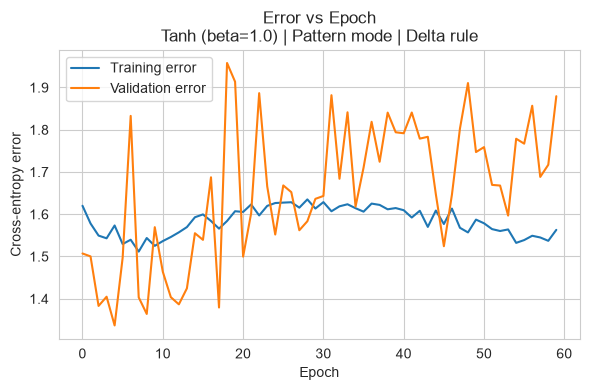

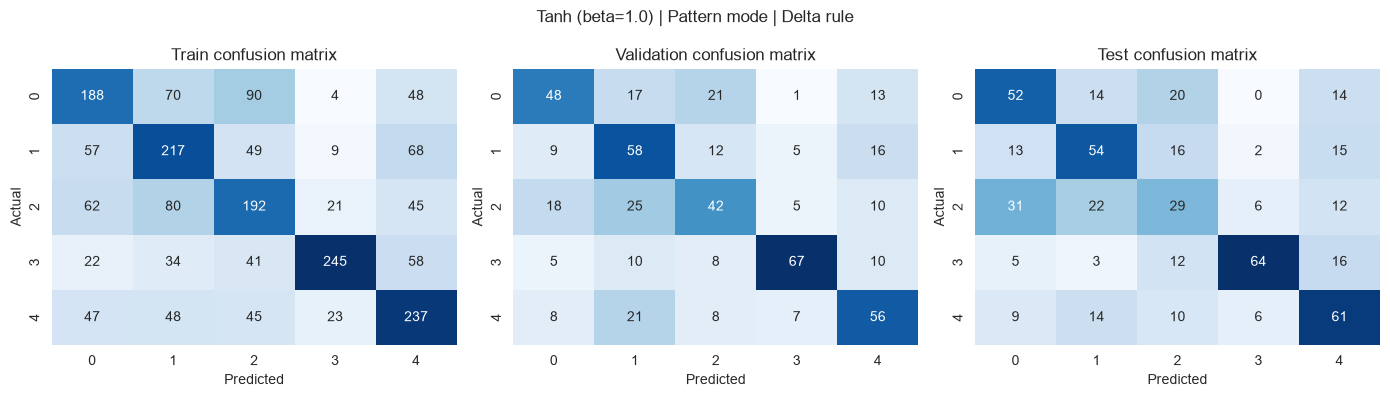

Accuracy -> train: 0.539 | val: 0.542 | test: 0.520
Training: Tanh (beta=1.0) | Pattern mode | Generalized delta rule
  epoch   1 | train loss 1.6230 | val loss 1.4886 | val acc 0.348
  epoch  20 | train loss 1.8088 | val loss 2.1408 | val acc 0.482
  epoch  40 | train loss 1.8875 | val loss 2.1114 | val acc 0.504
  epoch  60 | train loss 1.7833 | val loss 2.2210 | val acc 0.540
  reached max_epochs (60) without the stopping criterion firing -- this combination likely hasn't settled into a stable minimum


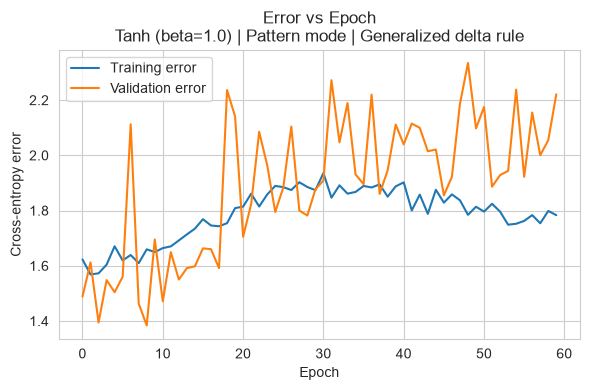

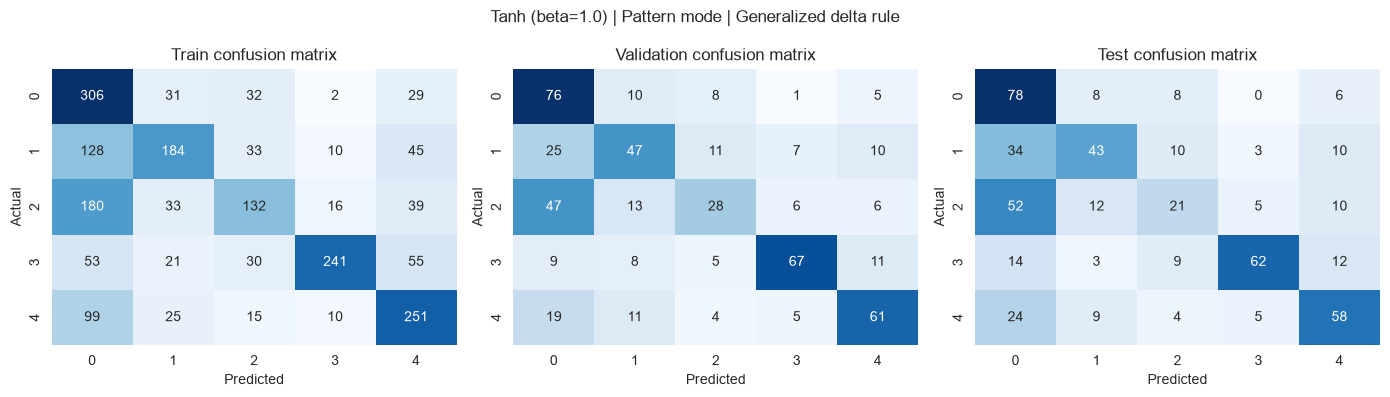

Accuracy -> train: 0.557 | val: 0.558 | test: 0.524
Training: Tanh (beta=1.0) | Pattern mode | AdaM rule
  epoch   1 | train loss 1.5624 | val loss 1.4448 | val acc 0.404
  epoch  20 | train loss 1.2030 | val loss 1.3356 | val acc 0.460
  epoch  40 | train loss 1.1656 | val loss 1.1519 | val acc 0.532
  epoch  60 | train loss 1.1122 | val loss 1.1429 | val acc 0.556
  reached max_epochs (60) without the stopping criterion firing -- this combination likely hasn't settled into a stable minimum


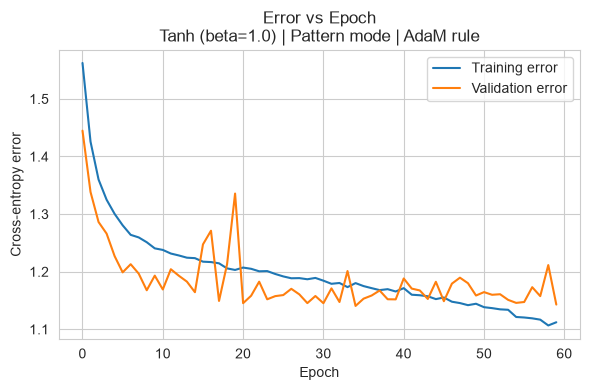

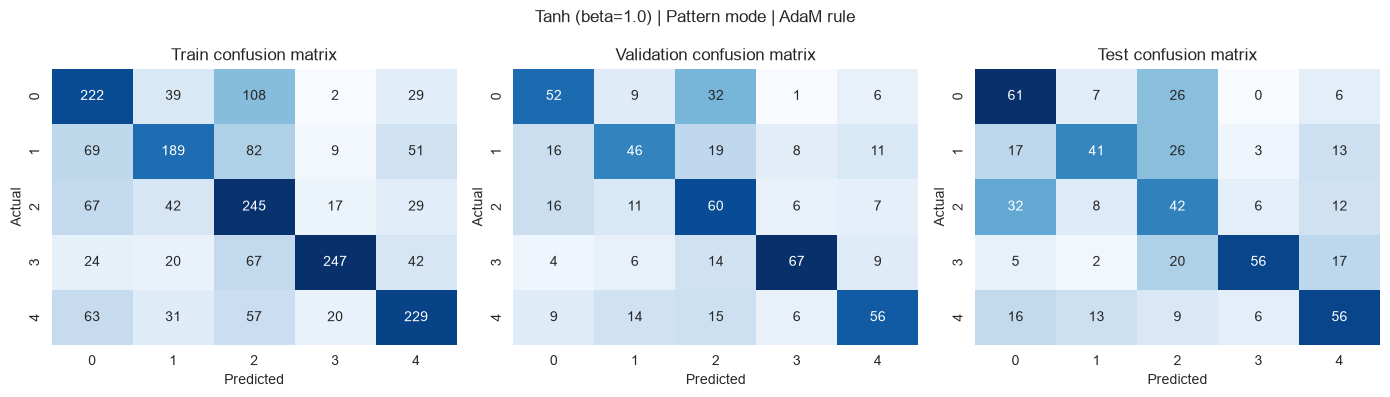

Accuracy -> train: 0.566 | val: 0.562 | test: 0.512
Training: Tanh (beta=1.0) | Mini-batch mode | Delta rule
  epoch   1 | train loss 1.6144 | val loss 1.6099 | val acc 0.204
  epoch  20 | train loss 1.5186 | val loss 1.4946 | val acc 0.372
  epoch  40 | train loss 1.3885 | val loss 1.3470 | val acc 0.474
  epoch  60 | train loss 1.3195 | val loss 1.2878 | val acc 0.484
  epoch  80 | train loss 1.2782 | val loss 1.2337 | val acc 0.502
  epoch 100 | train loss 1.2550 | val loss 1.2220 | val acc 0.512
  epoch 120 | train loss 1.2479 | val loss 1.2098 | val acc 0.516
  epoch 140 | train loss 1.2352 | val loss 1.1924 | val acc 0.528
  epoch 160 | train loss 1.2224 | val loss 1.1839 | val acc 0.510
  epoch 180 | train loss 1.2210 | val loss 1.1903 | val acc 0.530
  epoch 200 | train loss 1.2147 | val loss 1.1754 | val acc 0.514
  epoch 220 | train loss 1.2059 | val loss 1.1829 | val acc 0.532
  epoch 240 | train loss 1.2174 | val loss 1.1871 | val acc 0.530
  epoch 260 | train loss 1.2069 |

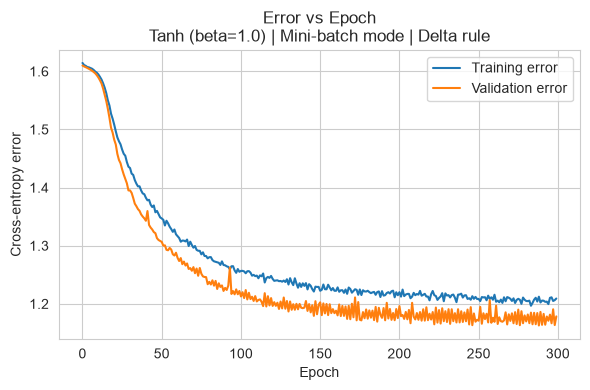

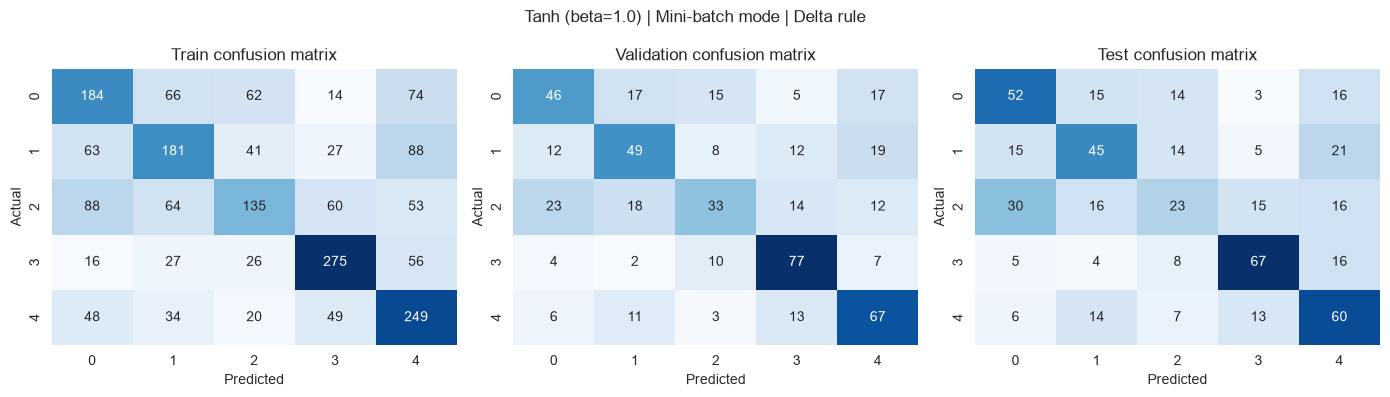

Accuracy -> train: 0.512 | val: 0.544 | test: 0.494
Training: Tanh (beta=1.0) | Mini-batch mode | Generalized delta rule
  epoch   1 | train loss 1.6152 | val loss 1.6100 | val acc 0.200
  epoch  20 | train loss 1.2355 | val loss 1.1918 | val acc 0.516
  epoch  40 | train loss 1.2272 | val loss 1.1721 | val acc 0.526
  epoch  60 | train loss 1.1904 | val loss 1.1758 | val acc 0.528
  epoch  80 | train loss 1.1771 | val loss 1.1500 | val acc 0.538
  epoch 100 | train loss 1.1887 | val loss 1.2143 | val acc 0.504
  epoch 120 | train loss 1.1503 | val loss 1.1585 | val acc 0.536
  epoch 140 | train loss 1.1757 | val loss 1.1545 | val acc 0.524
  epoch 160 | train loss 1.1277 | val loss 1.1519 | val acc 0.540
  epoch 180 | train loss 1.1058 | val loss 1.1641 | val acc 0.542
  epoch 200 | train loss 1.0843 | val loss 1.1699 | val acc 0.524
  epoch 220 | train loss 1.0768 | val loss 1.2150 | val acc 0.510
  epoch 240 | train loss 1.0344 | val loss 1.1838 | val acc 0.516
  epoch 260 | train l

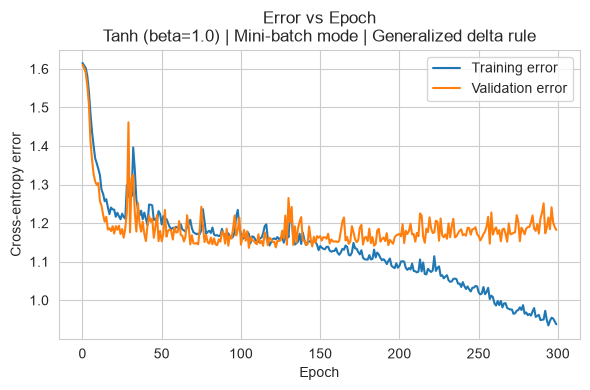

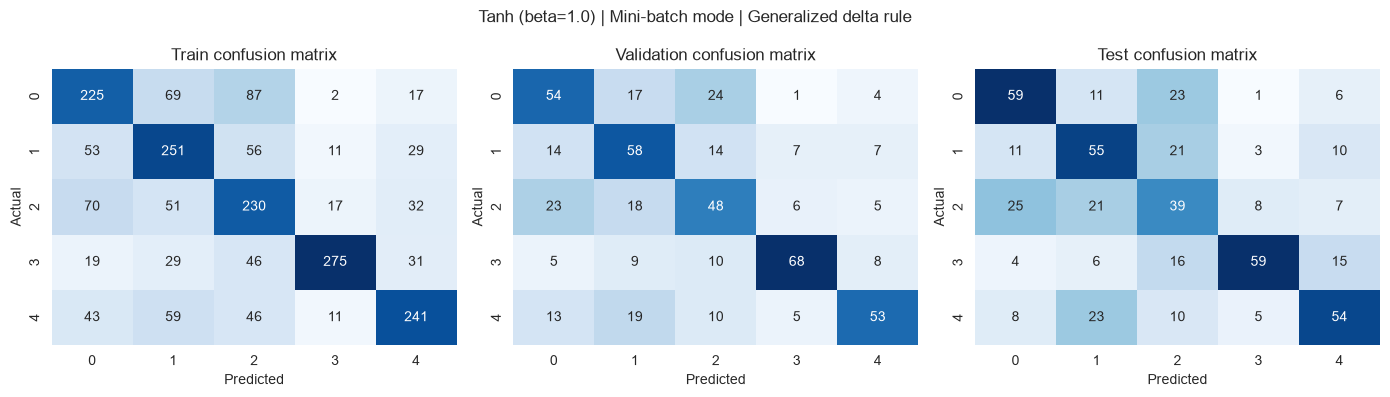

Accuracy -> train: 0.611 | val: 0.562 | test: 0.532
Training: Tanh (beta=1.0) | Mini-batch mode | AdaM rule
  epoch   1 | train loss 1.6152 | val loss 1.6126 | val acc 0.200
  epoch  20 | train loss 1.5232 | val loss 1.5047 | val acc 0.400
  epoch  40 | train loss 1.3986 | val loss 1.3595 | val acc 0.422
  epoch  60 | train loss 1.3277 | val loss 1.2864 | val acc 0.476
  epoch  80 | train loss 1.2821 | val loss 1.2412 | val acc 0.508
  epoch 100 | train loss 1.2448 | val loss 1.2056 | val acc 0.522
  epoch 120 | train loss 1.2157 | val loss 1.1815 | val acc 0.530
  epoch 140 | train loss 1.1968 | val loss 1.1675 | val acc 0.526
  stopping criterion met at epoch 153 (train error plateaued)


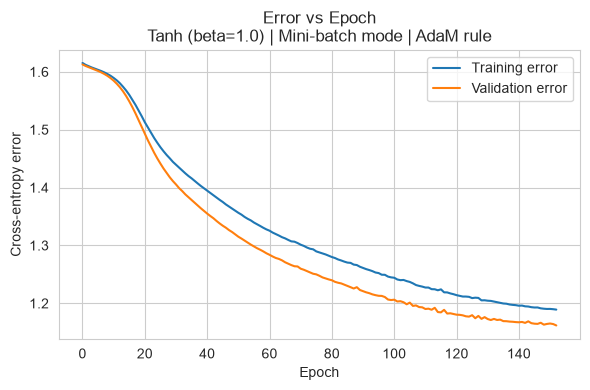

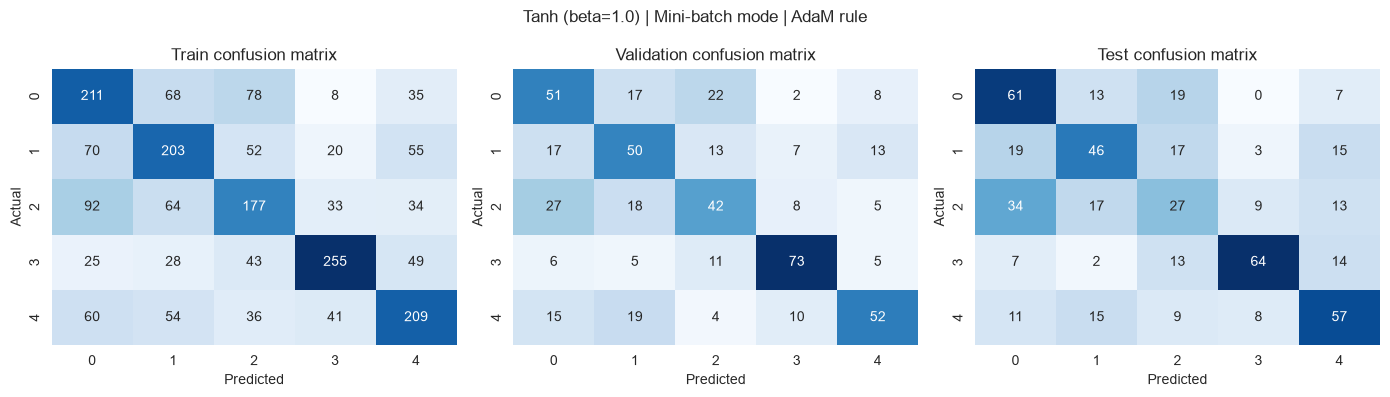

Accuracy -> train: 0.527 | val: 0.536 | test: 0.510
Training: ReLU | Pattern mode | Delta rule
  epoch   1 | train loss 1.6321 | val loss 1.6010 | val acc 0.200
  epoch  20 | train loss 1.6276 | val loss 1.5088 | val acc 0.514
  epoch  40 | train loss 1.5660 | val loss 1.8205 | val acc 0.526
  epoch  60 | train loss 1.5367 | val loss 2.0431 | val acc 0.550
  reached max_epochs (60) without the stopping criterion firing -- this combination likely hasn't settled into a stable minimum


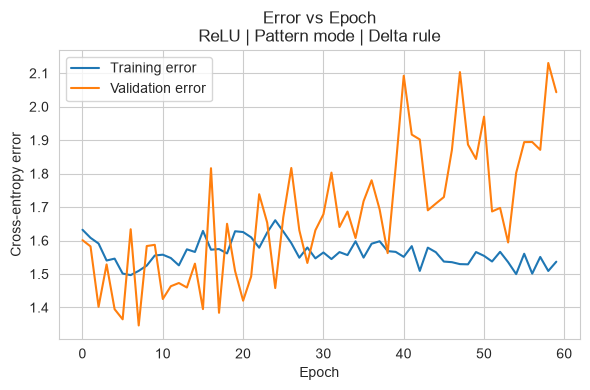

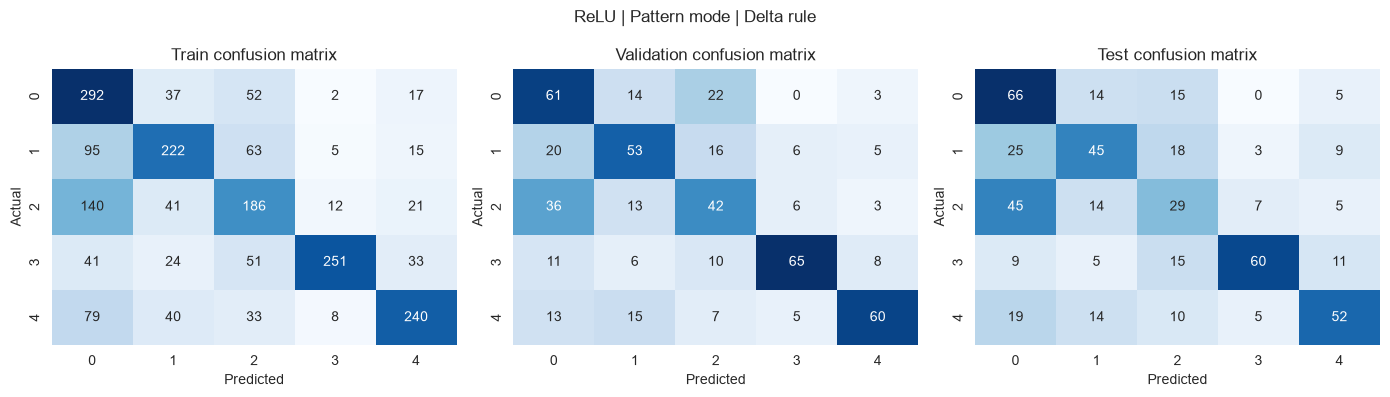

Accuracy -> train: 0.596 | val: 0.562 | test: 0.504
Training: ReLU | Pattern mode | Generalized delta rule
  epoch   1 | train loss 1.6338 | val loss 1.6175 | val acc 0.200
  epoch  20 | train loss 1.8465 | val loss 2.0262 | val acc 0.484
  epoch  40 | train loss 1.7894 | val loss 2.1651 | val acc 0.544
  epoch  60 | train loss 1.8116 | val loss 2.4414 | val acc 0.568
  reached max_epochs (60) without the stopping criterion firing -- this combination likely hasn't settled into a stable minimum


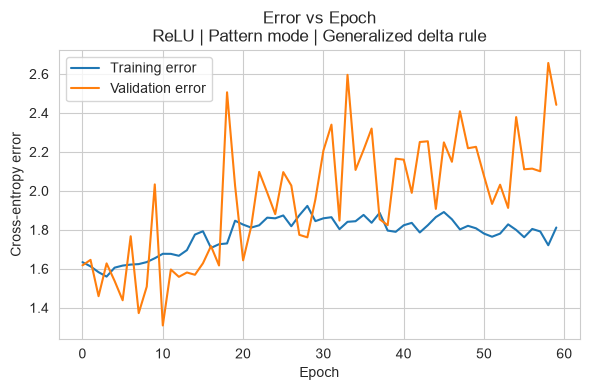

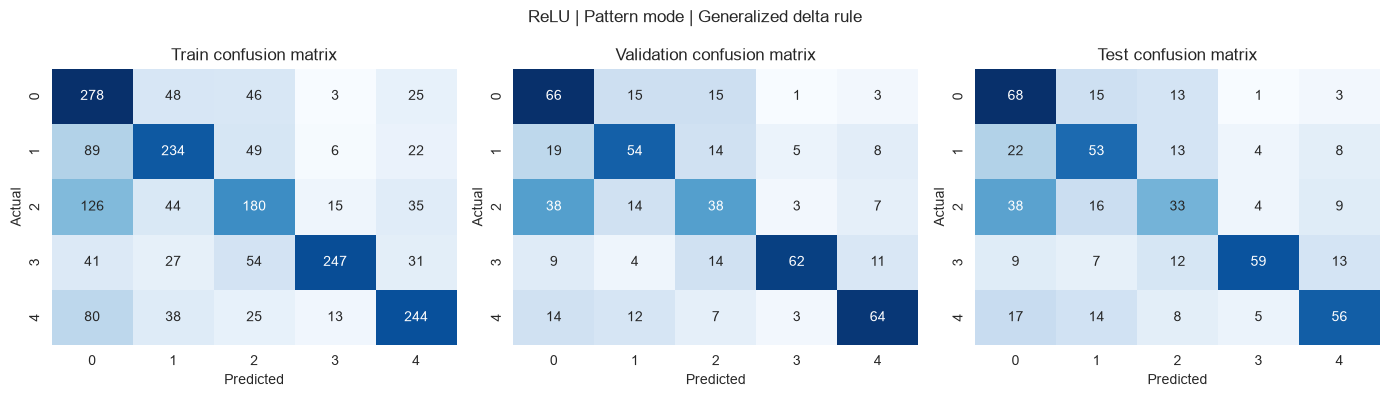

Accuracy -> train: 0.592 | val: 0.568 | test: 0.538
Training: ReLU | Pattern mode | AdaM rule
  epoch   1 | train loss 1.6002 | val loss 1.5466 | val acc 0.368
  epoch  20 | train loss 1.1333 | val loss 1.2446 | val acc 0.512
  epoch  40 | train loss 1.0282 | val loss 1.1690 | val acc 0.552
  epoch  60 | train loss 0.9489 | val loss 1.1904 | val acc 0.558
  reached max_epochs (60) without the stopping criterion firing -- this combination likely hasn't settled into a stable minimum


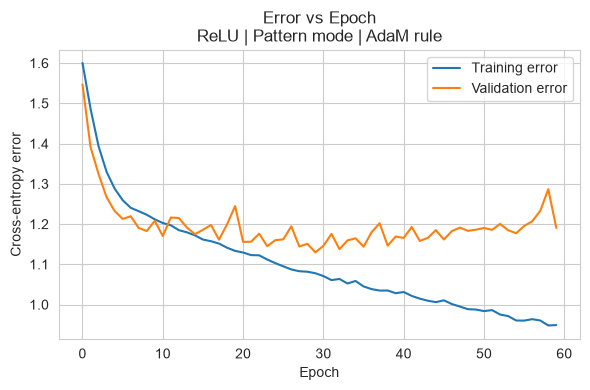

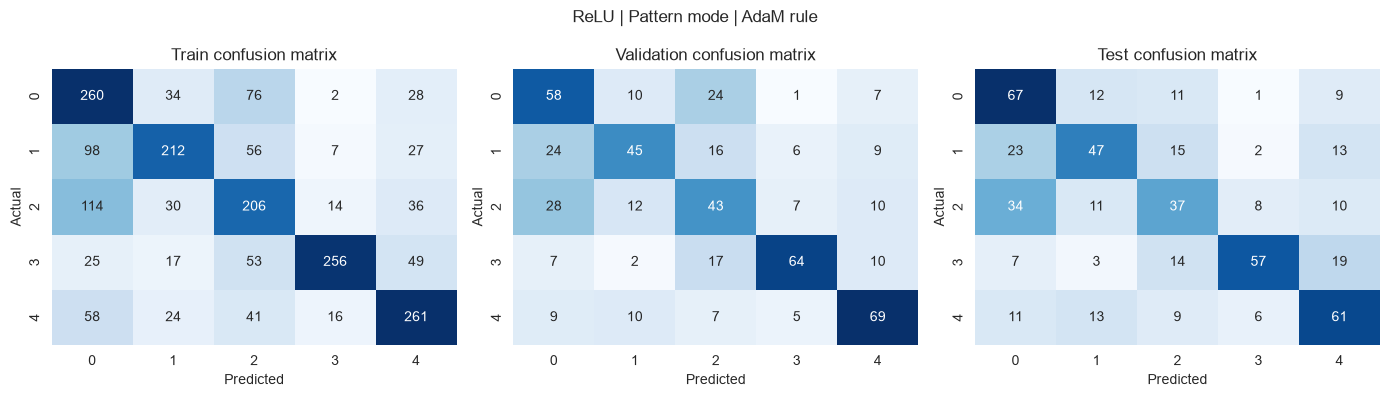

Accuracy -> train: 0.598 | val: 0.558 | test: 0.538
Training: ReLU | Mini-batch mode | Delta rule
  epoch   1 | train loss 1.6139 | val loss 1.6098 | val acc 0.200
  epoch  20 | train loss 1.5835 | val loss 1.5747 | val acc 0.310
  epoch  40 | train loss 1.4315 | val loss 1.3924 | val acc 0.446
  epoch  60 | train loss 1.3492 | val loss 1.3050 | val acc 0.464
  epoch  80 | train loss 1.3028 | val loss 1.2538 | val acc 0.490
  epoch 100 | train loss 1.2691 | val loss 1.2349 | val acc 0.500
  epoch 120 | train loss 1.2563 | val loss 1.2159 | val acc 0.498
  epoch 140 | train loss 1.2356 | val loss 1.1932 | val acc 0.520
  epoch 160 | train loss 1.2173 | val loss 1.1782 | val acc 0.522
  epoch 180 | train loss 1.2093 | val loss 1.1819 | val acc 0.518
  epoch 200 | train loss 1.2002 | val loss 1.1684 | val acc 0.524
  epoch 220 | train loss 1.1898 | val loss 1.1561 | val acc 0.532
  epoch 240 | train loss 1.1904 | val loss 1.1639 | val acc 0.528
  epoch 260 | train loss 1.1759 | val loss 1

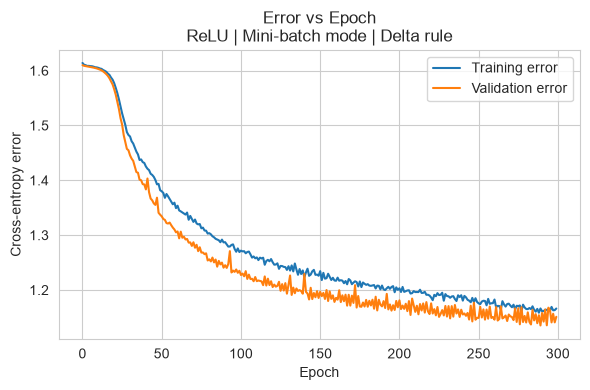

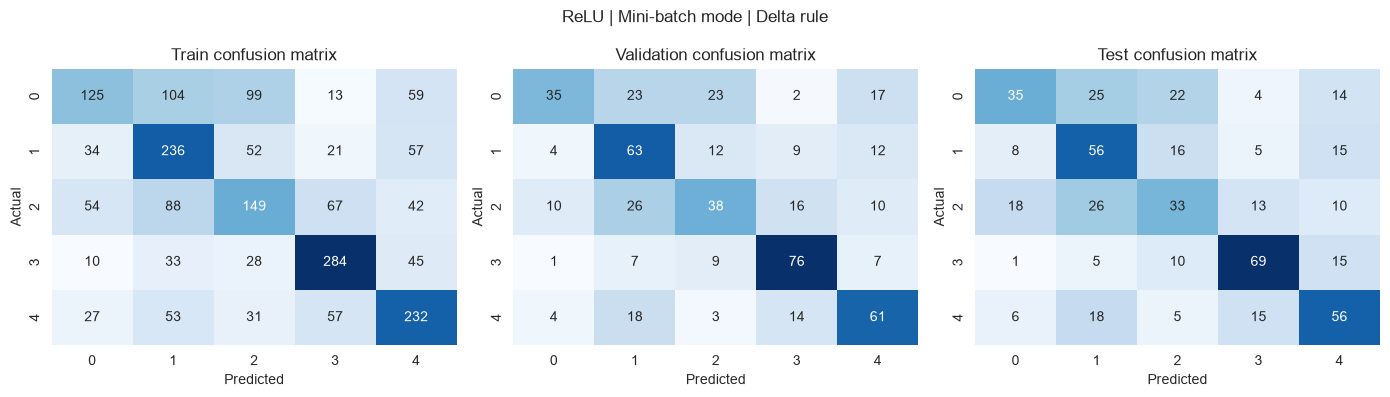

Accuracy -> train: 0.513 | val: 0.546 | test: 0.498
Training: ReLU | Mini-batch mode | Generalized delta rule
  epoch   1 | train loss 1.6139 | val loss 1.6100 | val acc 0.196
  epoch  20 | train loss 1.2846 | val loss 1.2421 | val acc 0.492
  epoch  40 | train loss 1.1818 | val loss 1.2271 | val acc 0.492
  epoch  60 | train loss 1.1433 | val loss 1.1754 | val acc 0.516
  epoch  80 | train loss 1.1091 | val loss 1.1699 | val acc 0.514
  epoch 100 | train loss 1.0530 | val loss 1.1122 | val acc 0.540
  epoch 120 | train loss 1.0139 | val loss 1.1734 | val acc 0.514
  epoch 140 | train loss 1.0321 | val loss 1.1505 | val acc 0.540
  epoch 160 | train loss 0.9662 | val loss 1.1853 | val acc 0.520
  epoch 180 | train loss 0.9366 | val loss 1.1883 | val acc 0.548
  epoch 200 | train loss 0.9424 | val loss 1.2085 | val acc 0.516
  epoch 220 | train loss 0.9432 | val loss 1.2234 | val acc 0.538
  epoch 240 | train loss 0.9036 | val loss 1.2982 | val acc 0.508
  epoch 260 | train loss 0.8840 

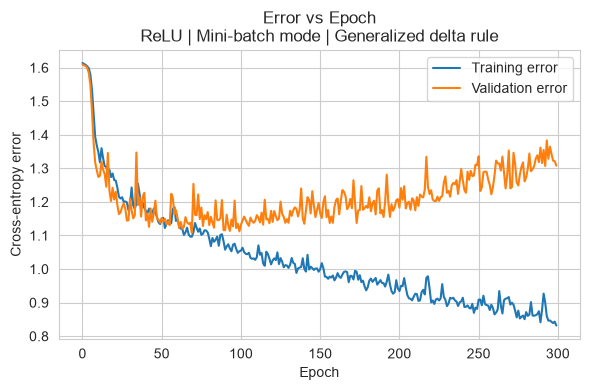

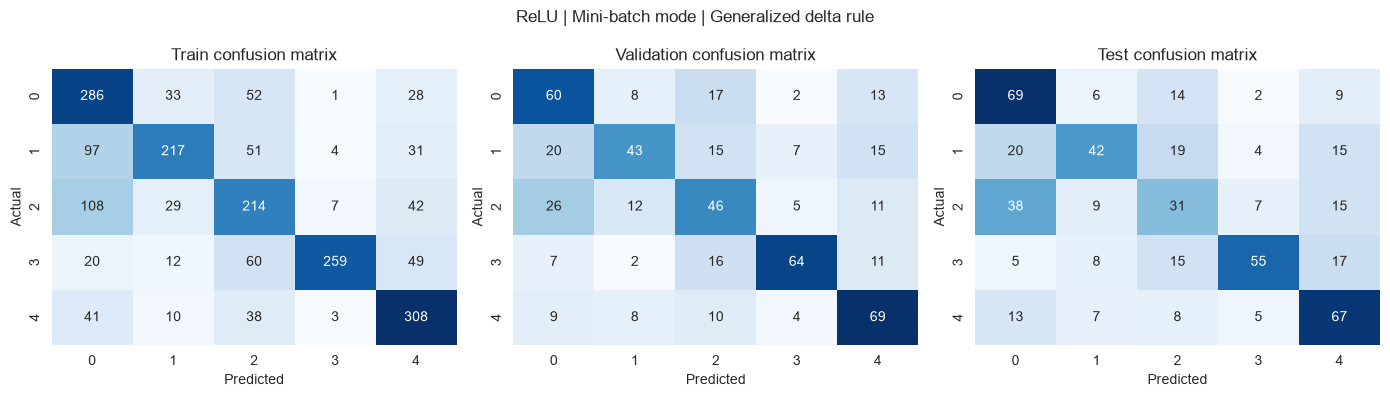

Accuracy -> train: 0.642 | val: 0.564 | test: 0.528
Training: ReLU | Mini-batch mode | AdaM rule
  epoch   1 | train loss 1.6150 | val loss 1.6133 | val acc 0.200
  epoch  20 | train loss 1.5580 | val loss 1.5481 | val acc 0.382
  epoch  40 | train loss 1.4024 | val loss 1.3734 | val acc 0.434
  epoch  60 | train loss 1.3027 | val loss 1.2692 | val acc 0.480
  epoch  80 | train loss 1.2360 | val loss 1.2087 | val acc 0.504
  epoch 100 | train loss 1.1995 | val loss 1.1789 | val acc 0.516
  epoch 120 | train loss 1.1777 | val loss 1.1656 | val acc 0.530
  epoch 140 | train loss 1.1607 | val loss 1.1551 | val acc 0.542
  epoch 160 | train loss 1.1453 | val loss 1.1456 | val acc 0.544
  epoch 180 | train loss 1.1316 | val loss 1.1359 | val acc 0.540
  stopping criterion met at epoch 182 (train error plateaued)


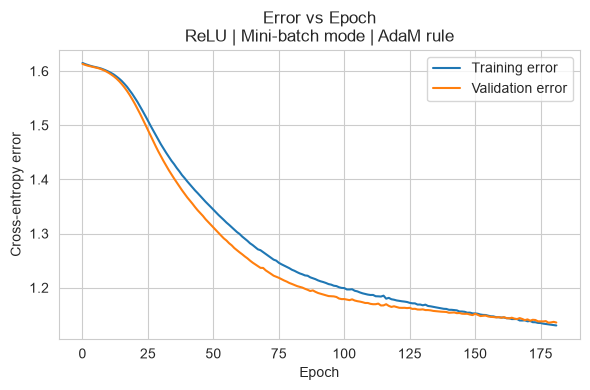

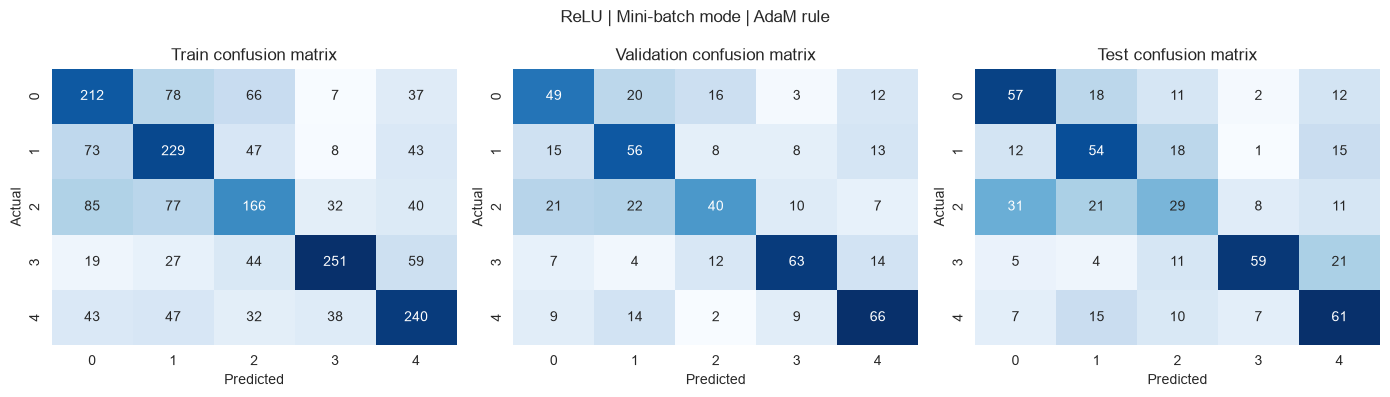

Accuracy -> train: 0.549 | val: 0.548 | test: 0.520


In [9]:
ACTIVATIONS = ["tanh", "relu"]          # Configuration1 = tanh, Configuration2 = relu
MODES       = ["pattern", "minibatch"]
RULES       = ["delta", "gdelta", "adam"]

LABELS = {"tanh": "Tanh (beta=1.0)", "relu": "ReLU",
          "pattern": "Pattern mode", "minibatch": "Mini-batch mode",
          "delta": "Delta rule", "gdelta": "Generalized delta rule", "adam": "AdaM rule"}

results = []

for activation in ACTIVATIONS:
    for mode in MODES:
        for rule in RULES:
            tag = f"{LABELS[activation]} | {LABELS[mode]} | {LABELS[rule]}"
            print("=" * 90)
            print("Training:", tag)

            model, history = train_model(activation, mode, rule)

            plot_error_curves(history, f"Error vs Epoch\n{tag}")

            acc_tr, cm_tr, _ = evaluate_model(model, X_train, y_train)
            acc_v,  cm_v,  _ = evaluate_model(model, X_val,   y_val)
            acc_te, cm_te, _ = evaluate_model(model, X_test,  y_test)

            plot_confusion_matrices(cm_tr, cm_v, cm_te, tag)

            print(f"Accuracy -> train: {acc_tr:.3f} | val: {acc_v:.3f} | test: {acc_te:.3f}")

            results.append({
                "Activation": LABELS[activation], "Mode": LABELS[mode], "Update rule": LABELS[rule],
                "Epochs run": history["epochs_run"],
                "Train acc": acc_tr, "Val acc": acc_v, "Test acc": acc_te,
            })

results_df = pd.DataFrame(results)

### **9. Baseline Results Summary**

A single table to compare all 12 combinations at a glance, sorted by test accuracy.

In [10]:
results_df_sorted = results_df.sort_values("Test acc", ascending=False).reset_index(drop=True)
display(results_df_sorted)

,Activation,Mode,Update rule,Epochs run,Train acc,Val acc,Test acc
0,ReLU,Pattern mode,Generalized delta rule,60,0.5915,0.568,0.538
1,ReLU,Pattern mode,AdaM rule,60,0.5975,0.558,0.538
2,Tanh (beta=1.0),Mini-batch mode,Generalized delta rule,300,0.6110,0.562,0.532
3,ReLU,Mini-batch mode,Generalized delta rule,300,0.6420,0.564,0.528
4,Tanh (beta=1.0),Pattern mode,Generalized delta rule,60,0.5570,0.558,0.524
5,Tanh (beta=1.0),Pattern mode,Delta rule,60,0.5395,0.542,0.520
6,ReLU,Mini-batch mode,AdaM rule,182,0.5490,0.548,0.520
7,Tanh (beta=1.0),Pattern mode,AdaM rule,60,0.5660,0.562,0.512
8,Tanh (beta=1.0),Mini-batch mode,AdaM rule,153,0.5275,0.536,0.510
9,ReLU,Pattern mode,Delta rule,60,0.5955,0.562,0.504


### **10. Experiment 2 — Normalization Study**

For Configuration2 (ReLU) + Mini-batch mode + AdaM rule, repeat training done with:

**10a.** **Mean-variance normalization** of the input features — standardize each feature using the training set's mean and standard deviation (z-score), applied to train/val/test consistently.

**10b.** **Layer normalization** — Instead of pre-processing the inputs, add a `nn.LayerNorm` layer after each hidden linear layer inside the network

Training: Config2 + Mini-batch + AdaM  |  Mean-variance normalized inputs
  epoch   1 | train loss 1.6172 | val loss 1.6070 | val acc 0.238
  epoch  20 | train loss 1.3204 | val loss 1.2865 | val acc 0.524
  epoch  40 | train loss 1.0722 | val loss 1.1039 | val acc 0.550
  epoch  60 | train loss 0.9855 | val loss 1.1021 | val acc 0.546
  epoch  80 | train loss 0.9259 | val loss 1.1186 | val acc 0.544
  epoch 100 | train loss 0.8757 | val loss 1.1369 | val acc 0.536
  epoch 120 | train loss 0.8329 | val loss 1.1661 | val acc 0.546
  epoch 140 | train loss 0.7953 | val loss 1.2047 | val acc 0.536
  epoch 160 | train loss 0.7629 | val loss 1.2541 | val acc 0.540
  epoch 180 | train loss 0.7355 | val loss 1.3087 | val acc 0.530
  epoch 200 | train loss 0.7117 | val loss 1.3583 | val acc 0.524
  epoch 220 | train loss 0.6897 | val loss 1.4010 | val acc 0.526
  epoch 240 | train loss 0.6707 | val loss 1.4445 | val acc 0.528
  epoch 260 | train loss 0.6530 | val loss 1.4891 | val acc 0.524
  

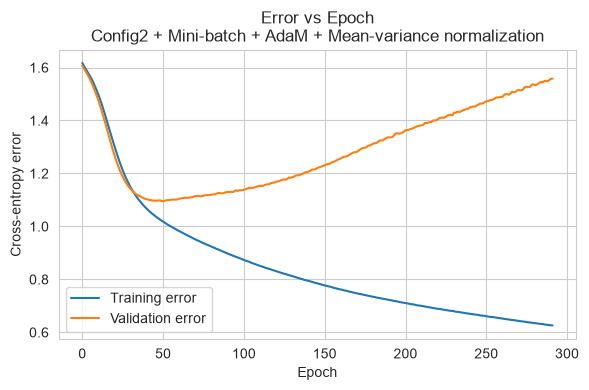

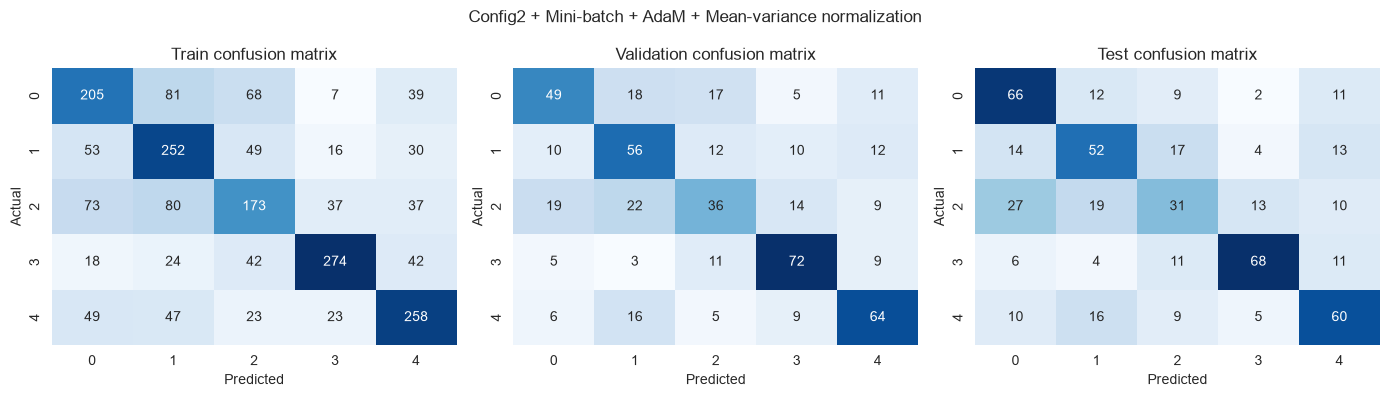

Accuracy -> train: 0.581 | val: 0.554 | test: 0.554


In [11]:
# ---- 10a. Mean-variance normalization of the input features ----
mean = X_train.mean(dim=0, keepdim=True)
std  = X_train.std(dim=0, keepdim=True) + 1e-8   # avoid divide-by-zero on constant features

X_train_norm = (X_train - mean) / std
X_val_norm   = (X_val   - mean) / std
X_test_norm  = (X_test  - mean) / std

print("Training: Config2 + Mini-batch + AdaM  |  Mean-variance normalized inputs")
model_meanvar, hist_meanvar = train_model(
    "relu", "minibatch", "adam",
    X_tr=X_train_norm, y_tr=y_train, X_v=X_val_norm, y_v=y_val,
)
plot_error_curves(hist_meanvar, "Error vs Epoch\nConfig2 + Mini-batch + AdaM + Mean-variance normalization")

acc_tr_mv, cm_tr_mv, _ = evaluate_model(model_meanvar, X_train_norm, y_train)
acc_v_mv,  cm_v_mv,  _ = evaluate_model(model_meanvar, X_val_norm,   y_val)
acc_te_mv, cm_te_mv, _ = evaluate_model(model_meanvar, X_test_norm,  y_test)
plot_confusion_matrices(cm_tr_mv, cm_v_mv, cm_te_mv, "Config2 + Mini-batch + AdaM + Mean-variance normalization")
print(f"Accuracy -> train: {acc_tr_mv:.3f} | val: {acc_v_mv:.3f} | test: {acc_te_mv:.3f}")

Training: Config2 + Mini-batch + AdaM  |  Layer normalization
  epoch   1 | train loss 1.6396 | val loss 1.6034 | val acc 0.242
  epoch  20 | train loss 1.3396 | val loss 1.3168 | val acc 0.488
  epoch  40 | train loss 1.1416 | val loss 1.1949 | val acc 0.504
  epoch  60 | train loss 1.0387 | val loss 1.1735 | val acc 0.526
  epoch  80 | train loss 0.9708 | val loss 1.1833 | val acc 0.538
  epoch 100 | train loss 0.9227 | val loss 1.2168 | val acc 0.522
  epoch 120 | train loss 0.8737 | val loss 1.2669 | val acc 0.532
  epoch 140 | train loss 0.8463 | val loss 1.2889 | val acc 0.526
  epoch 160 | train loss 0.8178 | val loss 1.3051 | val acc 0.522
  epoch 180 | train loss 0.7855 | val loss 1.3472 | val acc 0.512
  epoch 200 | train loss 0.7640 | val loss 1.3707 | val acc 0.532
  epoch 220 | train loss 0.7539 | val loss 1.4044 | val acc 0.498
  epoch 240 | train loss 0.7188 | val loss 1.4444 | val acc 0.512
  epoch 260 | train loss 0.7064 | val loss 1.4609 | val acc 0.518
  epoch 280 | 

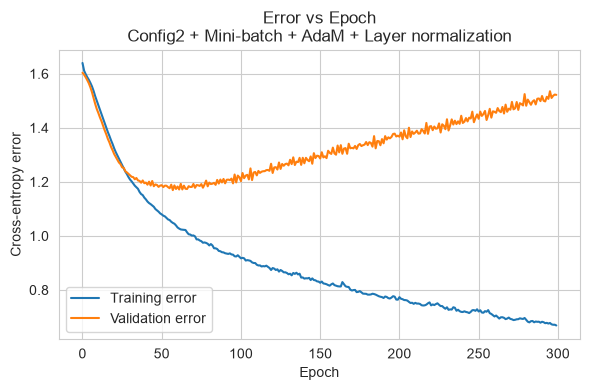

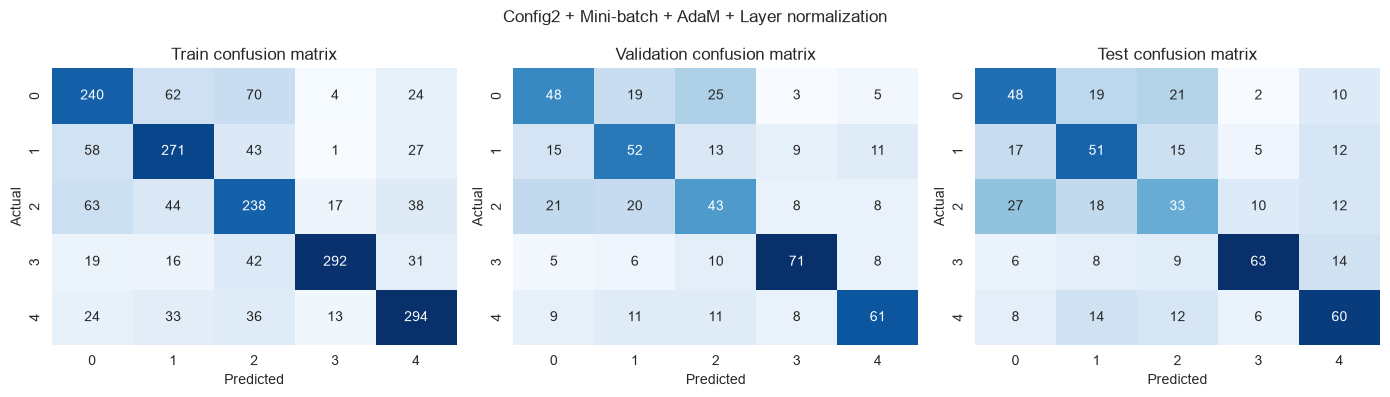

Accuracy -> train: 0.667 | val: 0.550 | test: 0.510


In [12]:
# ---- 10b. Layer normalization inside the network ----
print("Training: Config2 + Mini-batch + AdaM  |  Layer normalization")
model_ln, hist_ln = train_model("relu", "minibatch", "adam", use_layernorm=True)
plot_error_curves(hist_ln, "Error vs Epoch\nConfig2 + Mini-batch + AdaM + Layer normalization")

acc_tr_ln, cm_tr_ln, _ = evaluate_model(model_ln, X_train, y_train)
acc_v_ln,  cm_v_ln,  _ = evaluate_model(model_ln, X_val,   y_val)
acc_te_ln, cm_te_ln, _ = evaluate_model(model_ln, X_test,  y_test)
plot_confusion_matrices(cm_tr_ln, cm_v_ln, cm_te_ln, "Config2 + Mini-batch + AdaM + Layer normalization")
print(f"Accuracy -> train: {acc_tr_ln:.3f} | val: {acc_v_ln:.3f} | test: {acc_te_ln:.3f}")

### **11. Normalization Comparison**

Compare the plain (un-normalized) Config2 + Mini-batch + AdaM baseline from Section 8 against the two normalization variants above.

,Setup,Train acc,Val acc,Test acc
0,No normalization (baseline),0.5490,0.548,0.520
1,Mean-variance normalization,0.5810,0.554,0.554
2,Layer normalization,0.6675,0.550,0.510


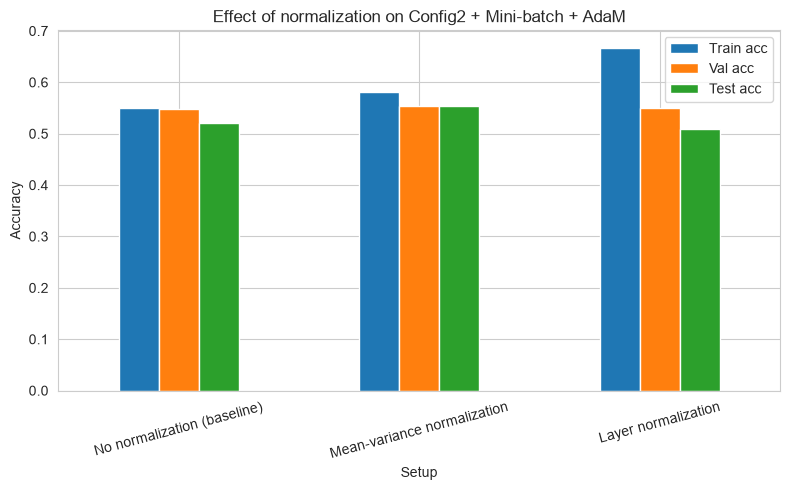

In [13]:
baseline_row = results_df[
    (results_df["Activation"] == "ReLU") &
    (results_df["Mode"] == "Mini-batch mode") &
    (results_df["Update rule"] == "AdaM rule")
].iloc[0]

norm_comparison = pd.DataFrame([
    {"Setup": "No normalization (baseline)", "Train acc": baseline_row["Train acc"],
     "Val acc": baseline_row["Val acc"], "Test acc": baseline_row["Test acc"]},
    {"Setup": "Mean-variance normalization", "Train acc": acc_tr_mv, "Val acc": acc_v_mv, "Test acc": acc_te_mv},
    {"Setup": "Layer normalization", "Train acc": acc_tr_ln, "Val acc": acc_v_ln, "Test acc": acc_te_ln},
])
display(norm_comparison)

norm_comparison.set_index("Setup")[["Train acc", "Val acc", "Test acc"]].plot(
    kind="bar", figsize=(8, 5), rot=15)
plt.ylabel("Accuracy")
plt.title("Effect of normalization on Config2 + Mini-batch + AdaM")
plt.tight_layout()
plt.show()

### **12. Observations**

- **Update rule:** AdaM converged faster in the mini-batch setting, stopping at 153–182 epochs, while most Delta and Generalized Delta runs reached the maximum epoch limit. This suggests AdaM was more stable.

- **Learning mode:** Pattern-mode runs generally reached their 60-epoch limit, while mini-batch runs could continue for more epochs. Pattern mode is more noisy because the weights are updated after every sample.

- **Activation function:** Tanh performed slightly better overall. It performed especially well with the **Generalized Delta Rule**, giving the highest test accuracy of **53.2%**.

- **Confusion matrices:** The most confused class pairs should be identified from the largest off-diagonal values in the test confusion matrices. The confusion is not necessarily symmetric.

- **Normalization:** Mean-variance normalization improved test accuracy from **51.4% to 55.4%**, while layer normalization slightly decreased it to **51.0%**. Therefore, mean-variance normalization helped more for this dataset.

### **Result & Conclusions**

- Among the 12 combinations, **Tanh + Mini-batch + Generalized Delta Rule** gives the highest test accuracy of **53.2%**.
- For the normalization experiment, **Mean-variance normalization** gives the best test accuracy of **55.4%**, slightly improving over the baseline **51.4%**.
- Layer normalization gives the highest training accuracy (**66.75%**), but its test accuracy is lower (**51.0%**), suggesting that the model does not generalize as well.